In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from pathlib import Path


In [ ]:
train_csv = Path("~/Workspace/ML_Project/data/processed/train.csv")
val_csv = Path("~/Workspace/ML_Project/data/processed/val.csv")
test_csv = Path("~/Workspace/ML_Project/data/processed/test.csv")

movies_csv = Path("~/Workspace/ML_Project/data/row/ml-latest-small/movies.csv")

train = pd.read_csv(train_csv)
val = pd.read_csv(val_csv)
test = pd.read_csv(test_csv)
movies = pd.read_csv(movies_csv)

print(train.shape, "\n")
print(val.shape, "\n")
print(test.shape, "\n")

print(train.head(5), "\n")
print(val.head(5), "\n")
print(test.head(5), "\n")




(60419, 7) 

(7545, 7) 

(7545, 7) 

(9742, 3)
   uid   iid  userId  movieId  rating  like  timestamp
0    0   451       1     1210     5.0     1  964980499
1    0   722       1     2018     5.0     1  964980523
2    0   904       1     2628     4.0     1  964980523
3    0   961       1     2826     4.0     1  964980523
4    0  1143       1     3578     5.0     1  964980668 

   uid  iid  userId  movieId  rating  like  timestamp
0    0  360       1      954     5.0     1  964983219
1    0  449       1     1208     4.0     1  964983250
2    0  813       1     2329     5.0     1  964983263
3    0  992       1     2959     5.0     1  964983282
4    0  458       1     1219     2.0     0  964983393 

   uid   iid  userId  movieId  rating  like  timestamp
0    0   800       1     2291     5.0     1  964983664
1    0   500       1     1270     5.0     1  964983705
2    0   473       1     1240     5.0     1  964983723
3    0   447       1     1206     5.0     1  964983737
4    0  1168       1

#### User-based CF

In [25]:
from scipy.sparse import csr_matrix
from sklearn.neighbors import NearestNeighbors
# Определяем названия колонок
user_col = "uid"
item_col = "iid"
rating_col = "rating"


# Оставляем необходимые столбцы
train_cf = train[[user_col, item_col, rating_col]].copy()
val_cf = val[[user_col, item_col, rating_col]].copy()
test_cf = test[[user_col, item_col, rating_col]].copy()

# Кодирование пользователей и фильмов
user_ids = train_cf[user_col].unique()
item_ids = train_cf[item_col].unique()

user_to_idx = {user: idx for idx, user in enumerate(user_ids)}
item_to_idx = {item: idx for idx, item in enumerate(item_ids)}

idx_to_user = {idx: user for user, idx in user_to_idx.items()}
idx_to_item = {idx: item for item, idx in item_to_idx.items()}

n_users = len(user_ids)
n_items = len(item_ids)

# Преобразование в числовые индексы
train_cf["user_idx"] = train_cf[user_col].map(user_to_idx)
train_cf["item_idx"] = train_cf[item_col].map(item_to_idx)

# Матрица взаимодействий User-Item
R = csr_matrix(
    (
        train_cf[rating_col].values,
        (train_cf["user_idx"].values, train_cf["item_idx"].values)
    ),
    shape=(n_users, n_items),
    dtype=np.float32
)

print("Users:", n_users)
print("Items:", n_items)
print("Interactions:", R.nnz)
print("Matrix density:", R.nnz / (n_users * n_items))

Users: 602
Items: 2097
Interactions: 60419
Matrix density: 0.047860652062668235


#### Для определения схожести используем косинусное расстояние, а для определения похожий пользователей kNN

In [26]:
K_NEIGHBORS = 30

# Ищем похожих пользователей
user_knn = NearestNeighbors(
    n_neighbors=min(K_NEIGHBORS + 1, n_users),
    metric="cosine",
    algorithm="brute",
    n_jobs=-1
)

user_knn.fit(R)

user_distances, user_neighbors = user_knn.kneighbors(R)

user_similarities = 1 - user_distances


In [27]:
def recommend_user_based(user_id, n_recommendations=10):
    if user_id not in user_to_idx:
        return pd.DataFrame(columns=["movieId", "score"])

    user_idx = user_to_idx[user_id]

    # Оценки пользователя
    user_ratings = R[user_idx]

    # Уже просмотренные фильмы
    seen_items = set(user_ratings.indices)

    # Словарь для накопления оценок фильмов
    scores = np.zeros(n_items, dtype=np.float32)
    sim_sums = np.zeros(n_items, dtype=np.float32)

    # Перебираем ближайших соседей
    for neighbor_idx, similarity in zip(
        user_neighbors[user_idx],
        user_similarities[user_idx]
    ):
        if neighbor_idx == user_idx or similarity <= 0:
            continue

        neighbor_ratings = R[neighbor_idx]

        items = neighbor_ratings.indices
        ratings = neighbor_ratings.data

        # Учитываем только фильмы, которые пользователь еще не оценивал
        mask = np.array([item not in seen_items for item in items])

        items = items[mask]
        ratings = ratings[mask]

        scores[items] += similarity * ratings
        sim_sums[items] += similarity

    # Нормализация оценок
    scores = np.divide(
        scores,
        sim_sums,
        out=np.zeros_like(scores),
        where=sim_sums > 0
    )

    # Исключаем просмотренные фильмы
    scores[list(seen_items)] = -np.inf

    # Выбираем лучшие рекомендации
    top_items = np.argsort(scores)[::-1][:n_recommendations]

    recommendations = pd.DataFrame({
        "movieId": [idx_to_item[idx] for idx in top_items],
        "score": scores[top_items]
    })

    recommendations = recommendations[
        np.isfinite(recommendations["score"])
    ]

    return recommendations.reset_index(drop=True)

In [36]:
example_user = train_cf[user_col].iloc[0]

recommendations = recommend_user_based(
    example_user,
    n_recommendations=10
)

# Соответствие iid -> movieId
iid_to_movie = train.drop_duplicates("iid").set_index("iid")["movieId"]

# Соответствие movieId -> title
movie_to_title = movies.drop_duplicates("movieId").set_index("movieId")["title"]

# Восстанавливаем movieId и названия фильмов
recommendations["iid"] = recommendations["movieId"]
recommendations["movieId"] = recommendations["iid"].map(iid_to_movie)
recommendations["title"] = recommendations["movieId"].map(movie_to_title)

print("User:", example_user)
display(recommendations[["iid", "movieId", "title", "score"]])

User: 0


,iid,movieId,title,score
0,1838,66934,Dr. Horrible's Sing-Along Blog (2008),5.0
1,131,272,"Madness of King George, The (1994)",5.0
2,1894,79702,Scott Pilgrim vs. the World (2010),5.0
3,472,1237,"Seventh Seal, The (Sjunde inseglet, Det) (1957)",5.0
4,1632,34162,Wedding Crashers (2005),5.0
5,1763,55118,Eastern Promises (2007),5.0
6,1711,48738,"Last King of Scotland, The (2006)",5.0
7,1871,72998,Avatar (2009),5.0
8,1172,3730,"Conversation, The (1974)",5.0
9,1027,3083,All About My Mother (Todo sobre mi madre) (1999),5.0


#### Item-based CF

In [38]:
# Транспонированная матрица Item-User
R_T = R.T.tocsr()

# Количество похожих фильмов
K_ITEMS = 30

item_knn = NearestNeighbors(
    n_neighbors=min(K_ITEMS + 1, n_items),
    metric="cosine",
    algorithm="brute",
    n_jobs=-1
)

item_knn.fit(R_T)

item_distances, item_neighbors = item_knn.kneighbors(R_T)

item_similarities = 1 - item_distances


In [39]:
def recommend_item_based(user_id, n_recommendations=10):
    if user_id not in user_to_idx:
        return pd.DataFrame(columns=["movieId", "score"])

    user_idx = user_to_idx[user_id]

    user_ratings = R[user_idx]

    # Фильмы, которые пользователь уже оценивал
    seen_items = set(user_ratings.indices)

    scores = np.zeros(n_items, dtype=np.float32)
    sim_sums = np.zeros(n_items, dtype=np.float32)

    # Перебираем фильмы, оцененные пользователем
    for item_idx, rating in zip(
        user_ratings.indices,
        user_ratings.data
    ):
        # Похожие фильмы
        neighbors = item_neighbors[item_idx]
        similarities = item_similarities[item_idx]

        for neighbor_idx, similarity in zip(neighbors, similarities):

            if neighbor_idx == item_idx or similarity <= 0:
                continue

            if neighbor_idx in seen_items:
                continue

            scores[neighbor_idx] += similarity * rating
            sim_sums[neighbor_idx] += similarity

    # Нормализация
    scores = np.divide(
        scores,
        sim_sums,
        out=np.zeros_like(scores),
        where=sim_sums > 0
    )

    # Исключаем просмотренные фильмы
    scores[list(seen_items)] = -np.inf

    top_items = np.argsort(scores)[::-1][:n_recommendations]

    recommendations = pd.DataFrame({
        "movieId": [idx_to_item[idx] for idx in top_items],
        "score": scores[top_items]
    })

    recommendations = recommendations[
        np.isfinite(recommendations["score"])
    ]

    return recommendations.reset_index(drop=True)

In [ ]:
example_user = train_cf[user_col].iloc[0]

recommendations = recommend_item_based(
    example_user,recommend_user_based
    n_recommendations=10
)

# Соответствие iid -> movieId
iid_to_movie = train.drop_duplicates("iid").set_index("iid")["movieId"]

# Соответствие movieId -> title
movie_to_title = movies.drop_duplicates("movieId").set_index("movieId")["title"]

# Восстанавливаем movieId и названия фильмов
recommendations["iid"] = recommendations["movieId"]
recommendations["movieId"] = recommendations["iid"].map(iid_to_movie)
recommendations["title"] = recommendations["movieId"].map(movie_to_title)

print("User:", example_user)
display(recommendations[["iid", "movieId", "title", "score"]])

User: 0


,iid,movieId,title,score
0,1583,8961,"Incredibles, The (2004)",5.0
1,869,2471,Crocodile Dundee II (1988),5.0
2,898,2599,Election (1999),5.0
3,765,2126,Snake Eyes (1998),5.0
4,449,1208,Apocalypse Now (1979),5.0
5,777,2146,St. Elmo's Fire (1985),5.0
6,447,1206,"Clockwork Orange, A (1971)",5.0
7,1530,7361,Eternal Sunshine of the Spotless Mind (2004),5.0
8,1424,5989,Catch Me If You Can (2002),5.0
9,480,1247,"Graduate, The (1967)",5.0


#### Оценка качества рекомендаций

In [42]:
# Релевантные фильмы для каждого пользователя
RELEVANCE_THRESHOLD = 4.0

val_relevant = (
    val_cf[val_cf[rating_col] >= RELEVANCE_THRESHOLD]
    .groupby(user_col)[item_col]
    .apply(set)
    .to_dict()
)

# Оставляем только пользователей, присутствующих в train
val_relevant = {
    user: items
    for user, items in val_relevant.items()
    if user in user_to_idx
}

print("Users for evaluation:", len(val_relevant))

Users for evaluation: 558


In [44]:
# Реализация метрик
def precision_at_k(recommended, relevant, k):
    recommended = recommended[:k]

    if len(recommended) == 0:
        return 0.0

    hits = len(set(recommended) & relevant)

    return hits / k


def recall_at_k(recommended, relevant, k):
    if len(relevant) == 0:
        return 0.0

    recommended = recommended[:k]

    hits = len(set(recommended) & relevant)

    return hits / len(relevant)


def ndcg_at_k(recommended, relevant, k):
    recommended = recommended[:k]

    dcg = 0.0

    for rank, item in enumerate(recommended):
        if item in relevant:
            dcg += 1 / np.log2(rank + 2)

    ideal_hits = min(len(relevant), k)

    idcg = sum(
        1 / np.log2(rank + 2)
        for rank in range(ideal_hits)
    )

    if idcg == 0:
        return 0.0

    return dcg / idcg

In [45]:
def evaluate_model(recommendation_function, val_relevant, k=10):

    precision_scores = []
    recall_scores = []
    ndcg_scores = []

    for user_id, relevant_items in val_relevant.items():

        recommendations = recommendation_function(
            user_id,
            n_recommendations=k
        )

        recommended_items = recommendations["movieId"].tolist()

        precision_scores.append(
            precision_at_k(recommended_items, relevant_items, k)
        )

        recall_scores.append(
            recall_at_k(recommended_items, relevant_items, k)
        )

        ndcg_scores.append(
            ndcg_at_k(recommended_items, relevant_items, k)
        )

    return {
        f"Precision@{k}": np.mean(precision_scores),
        f"Recall@{k}": np.mean(recall_scores),
        f"NDCG@{k}": np.mean(ndcg_scores)
    }

#### Создадим случайную рекомендацию

In [65]:
def recommend_random_based(user_id, n_recommendations=10):
    if user_id not in user_to_idx:
        return pd.DataFrame(columns=["movieId", "score"])

    seen_movies = set(
        train[train["uid"] == user_to_idx[user_id]]["iid"]
    )

    candidates = train[~train["iid"].isin(seen_movies)]

    if candidates.empty:
        return pd.DataFrame(columns=["movieId", "score"])

    recommendations = candidates.drop_duplicates("iid").sample(
        n=min(n_recommendations, candidates["iid"].nunique())
    )

    recommendations = recommendations[["movieId"]].copy()
    recommendations["score"] = 5.0

    return recommendations.reset_index(drop=True)

In [66]:
K = 20

user_results = evaluate_model(
    recommend_user_based,
    val_relevant,
    k=K
)

item_results = evaluate_model(
    recommend_item_based,
    val_relevant,
    k=K
)

random_results = evaluate_model(
    recommend_random_based,
    val_relevant,
    k=K
)

results = pd.DataFrame(
    [user_results, item_results, random_results],
    index=["User-based CF", "Item-based CF", "Random-based CF"]
)

display(results)

,Precision@20,Recall@20,NDCG@20
User-based CF,0.006362,0.031549,0.014891
Item-based CF,0.010932,0.045728,0.023811
Random-based CF,0.001344,0.004303,0.002711


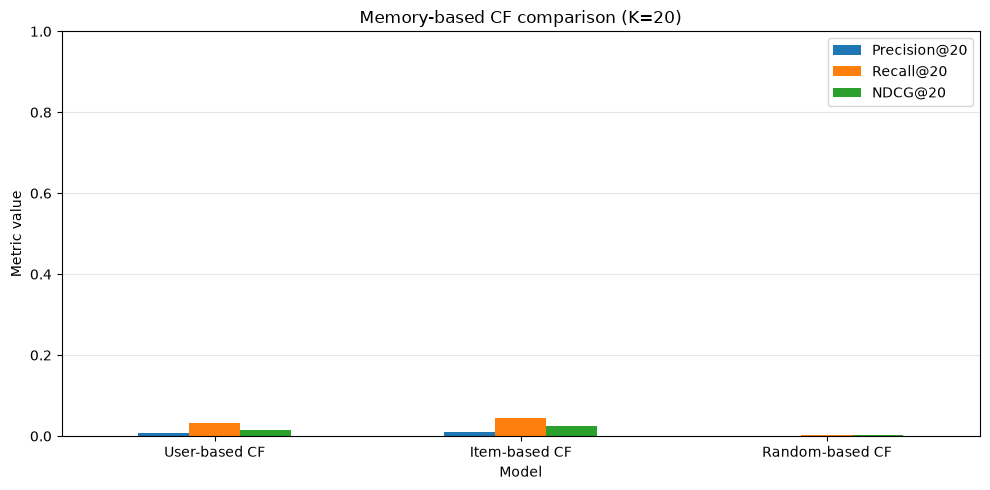

In [64]:
results.plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 1),
    rot=0
)

plt.title(f"Memory-based CF comparison (K={K})")
plt.ylabel("Metric value")
plt.xlabel("Model")
plt.legend(loc="best")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()